In [1]:
#####     Supplementary Materials (1)      #####
#####     Tree Cover Mask     #####
import numpy as np
from joblib import load
import rasterio
rng = np.random.default_rng(seed=42)  # 随机数生成器

import scipy.stats as stats
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)

import _calGlobal
factor = 1e-7  # 单位换算系数 (MgC/ha -> PgC)
def getGlobal(x, **kwargs):
    return _calGlobal.getGlobalSum(x, factor=factor, **kwargs)

def flipImage(tiff:np.ndarray):
    """Flip latitude and shift longitude from 0-360 to -180-180 style layout."""
    tiff = np.flip(tiff, axis=0)
    temp = np.zeros_like(tiff)
    temp[:, :180] = tiff[:, 180:]
    temp[:, 180:] = tiff[:, :180]
    tiff = temp
    return tiff

def PlotImg(data:np.ndarray, title:str="", cmap:str="YlGn",
            vmin:float=None, vmax:float=None, cbar:bool=True):
    ax = plt.axes(projection=ccrs.Robinson())
    ax.coastlines(color="gray", linewidth=0.5)
    img = ax.pcolormesh(lon, lat[30:], data[30:], cmap=cmap, vmin=vmin, vmax=vmax,
                        transform=ccrs.PlateCarree(), shading="flat")
    ax.set_title(title)
    if cbar:
        plt.colorbar(img, ax=ax, shrink=0.8, pad=0.05, orientation="horizontal")
    plt.show()
    plt.close()


In [2]:
### ---------- Load Data ---------- ###
ESAv7_data = np.load("./Data/AGBC_ESAv7.npz")
ESAv7_std = np.load("./Data/AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_data.items()}
ESAv7_std = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_std.items()}
print("ESACCI V7:", ESAv7_data.keys())

# Extract mean and std of ESACCI V7
ESA_data = ESAv7_data["Mean"].copy()
ESA_std = ESAv7_std["Mean"].copy()

# Load CMIP6 data
### cRoot Ratio 不再使用 0.8 填充，而是 MME
CMIP_set = np.load("./Data/CMIP6_AGBC.npz")
modelNum = len(CMIP_set)  # 模型数量：30
modelNames = list(CMIP_set.keys())
# Original CMIP6 maps (N, lat, lon)
CMIP_list0 = [np.array(val, dtype=np.float32) for val in CMIP_set.values()]
CMIP_data0:np.ndarray = np.stack(CMIP_list0, axis=0)
print(f"CMIP Models: {modelNum}")
print(modelNames)
# CMIP6 TreeFrac
CMIP_raw:dict = load("./Data/CMIP6_raw.joblib")
TreeFrac = [val["treeFrac"] for val in CMIP_raw.values()]
TreeFrac = np.stack([tf for tf in TreeFrac if tf is not None], axis=0)

with rasterio.open("./Data/Koppen_2010.tif", "r") as src:
    Koppen = src.read(1).astype(np.float32)
    Koppen = flipImage(Koppen)

ValidMask = (Koppen > 0) & (ESA_data > 0)
Koppen[~ValidMask] = np.nan
ESA_data[~ValidMask] = np.nan
ESA_std[~ValidMask] = np.nan
CMIP_data0[:, ~ValidMask] = np.nan

TreeMask = load("./Data/Masks/treemask.joblib")

### Climate Zone Mask
cliDict = {
    "Af": [1],  # 热带雨林
    "Am": [2],  # 热带季风
    "Aw": [3],  # 热带萨瓦纳
    "BW": [4, 5], # 干旱沙漠
    "BS": [6, 7], # 半干旱草原
    "Cs": [8, 9, 10], # 亚热带夏干（地中海）
    "Cw": [11, 12, 13], # 亚热带冬干
    "Cf": [14, 15, 16], # 亚热带全湿
    "Ds": [17, 18, 19, 20], # 寒温带夏干
    "Dw": [21, 22, 23, 24], # 寒温带冬干
    "Df": [25, 26, 27, 28], # 寒温带全湿
    "ET": [29],  # 极地苔原
    #"EF": [30]   # 极地冰原
    }
# f=全湿，s=夏干，w=冬干
cliMask = [np.isin(Koppen, ids) for ids in cliDict.values()] ### Climate Mask


ESACCI V7: dict_keys(['2010', '2011', '2012', '2015', 'Mean'])
CMIP Models: 30
['ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CanESM5', 'CESM2-FV2', 'CESM2-WACCM-FV2', 'CESM2-WACCM', 'CESM2', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-ESM2-1', 'E3SM-1-1-ECA', 'E3SM-1-1', 'EC-Earth3-CC', 'EC-Earth3-Veg-LR', 'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'IPSL-CM6A-LR-INCA', 'IPSL-CM6A-LR', 'KIOST-ESM', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'NorCPM1', 'NorESM2-LM', 'NorESM2-MM', 'SAM0-UNICON', 'TaiESM1', 'UKESM1-0-LL', 'UKESM1-1-LL']


TreeCover simulations VS observations
 > Tree Cover (Hansen)
28.2% ± 27.2


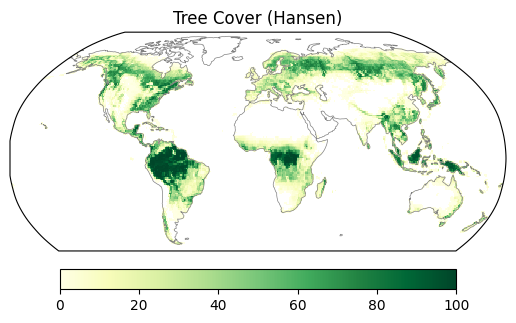

 > Tree Cover (JRC)
42.0% ± 34.3


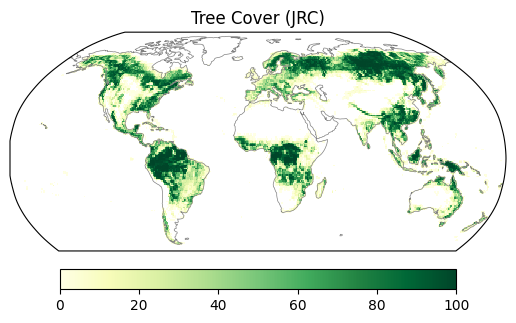

 > Tree Frac (CMIP6 MME)
(12, 180, 360)
25.0% ± 23.7


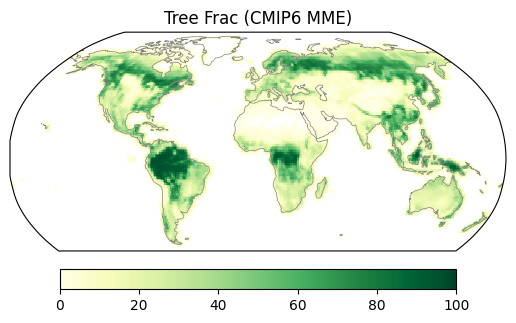

TP= 183.0,  FN= 19.8,  FP= 25.8 PgC


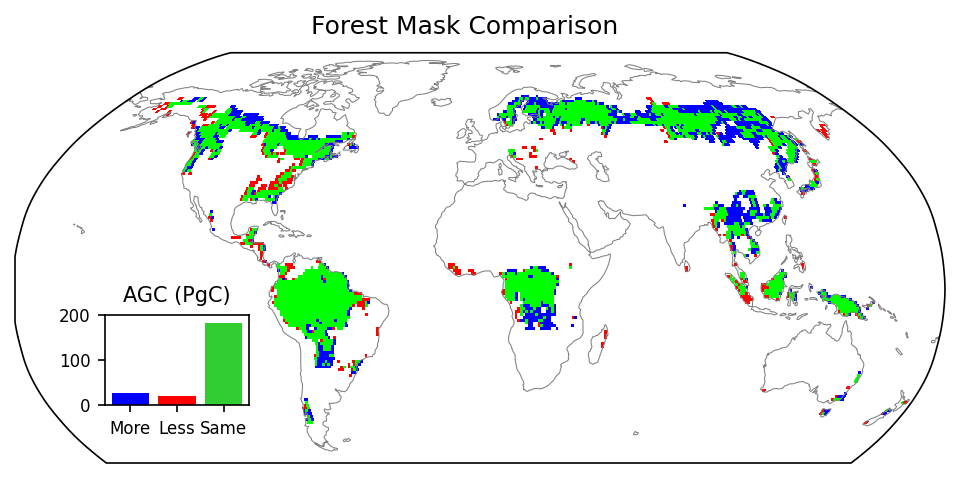

In [3]:
### ----- Supplementary Figure 1 ----- ###
print("TreeCover simulations VS observations")
# tree cover obs (Hansen yr2000)
print(" > Tree Cover (Hansen)")
with rasterio.open("./RawData/Veg/TreeCover.tif", "r") as src:
    TreeCover1 = src.read(1).astype(np.float32)
    TreeCover1[TreeCover1 <= 0.1] = np.nan  # 0.1%
TreeCover1 = flipImage(TreeCover1)
print(f"{np.nanmean(TreeCover1):.1f}% ± {np.nanstd(TreeCover1):.1f}")
PlotImg(TreeCover1, title="Tree Cover (Hansen)", vmin=0, vmax=100)

# tree cover obs (JRC yr2020)
print(" > Tree Cover (JRC)")
with rasterio.open("./RawData/Veg/ForestCover.tif", "r") as src:
    TreeCover2 = src.read(1).astype(np.float32)
    TreeCover2[TreeCover2 <= 0.1] = np.nan  # 0.1%
TreeCover2 = flipImage(TreeCover2)
print(f"{np.nanmean(TreeCover2):.1f}% ± {np.nanstd(TreeCover2):.1f}")
PlotImg(TreeCover2, title="Tree Cover (JRC)", vmin=0, vmax=100)

# tree frac sim
print(" > Tree Frac (CMIP6 MME)")
print(TreeFrac.shape)
TreeFrac[np.isnan(TreeFrac)] = 0  # view NaN as Zero!
treeFrac = np.mean(TreeFrac, axis=0) * 100
treeFrac[treeFrac <= 0.1] = np.nan  # 0.1%
print(f"{np.nanmean(treeFrac):.1f}% ± {np.nanstd(treeFrac):.1f}")
PlotImg(treeFrac, title="Tree Frac (CMIP6 MME)", vmin=0, vmax=100)

treemask0 = ValidMask & TreeMask  # (TreeFrac > 50) & ValidMask
treemask1 = ValidMask & (TreeCover1 > 50)  # Hansen tree cover
compare = np.full_like(TreeCover1, np.nan, dtype=np.float16)
compare[treemask0 & treemask1] = 1
compare[~treemask0 & treemask1] = 0  # MME FN 低估 (red)
compare[treemask0 & ~treemask1] = -1  # MME FP 高估 (blue)

TP = getGlobal(ESA_data, mask=(compare==1))
FN = getGlobal(ESA_data, mask=(compare==0))
FP = getGlobal(ESA_data, mask=(compare==-1))
print(f"TP= {TP:.1f},  FN= {FN:.1f},  FP= {FP:.1f} PgC")
# TP = 171.5,  FN = 16.1,  FP = 29.4 PgC

fig, ax = plt.subplots(figsize=(8, 4), dpi=150,
        subplot_kw={"projection": ccrs.Robinson()})
# Tree mask map
ax.coastlines(color="gray", linewidth=0.5)
img = ax.pcolormesh(lon, lat[30:], compare[30:], cmap="brg",
        transform=ccrs.PlateCarree(), shading="flat")
ax = fig.add_axes([0.2, 0.25, 0.12, 0.15])  # left, bottom, width, height
# Bar chart
ax.bar([-1, 0, 1], [FP, FN, TP], color=["blue", "red", "limegreen"])
ax.set_xticks([-1, 0, 1], ["More", "Less", "Same"], fontsize=8)
ax.set_yticks([0, 100, 200], ["0", "100", "200"], fontsize=8)
ax.set_title("AGC (PgC)", fontsize=10)
fig.suptitle("Forest Mask Comparison", fontsize=12, y=0.9, ha="center")

plt.show(fig)
plt.close(fig)


New fig.1 under Hansen tree mask
CCI-v7 Mean:  202.8 PgC   (302.8)
CMIP6 MME:  208.8 PgC ± 65.1 (421.9 ± 128.6)
 	Af	Am	Aw	BW	BS	Cs	Cw	Cf	Ds	Dw	Df	ET
ESA-v7:	69.68	39.25	26.55	0.00	0.11	1.74	5.96	12.91	1.51	4.21	40.70	0.14
CMIP6:	80.22	38.63	29.62	0.00	0.19	0.95	5.25	13.05	0.79	4.39	35.62	0.09
Diff:	10.54	-0.62	3.07	--	0.08	-0.79	-0.71	0.14	-0.72	0.18	-5.08	-0.05
 	+15.1%	-1.6%	+11.6%	--	+68.0%	-45.5%	-11.9%	+1.1%	-47.9%	+4.4%	-12.5%	-37.4%


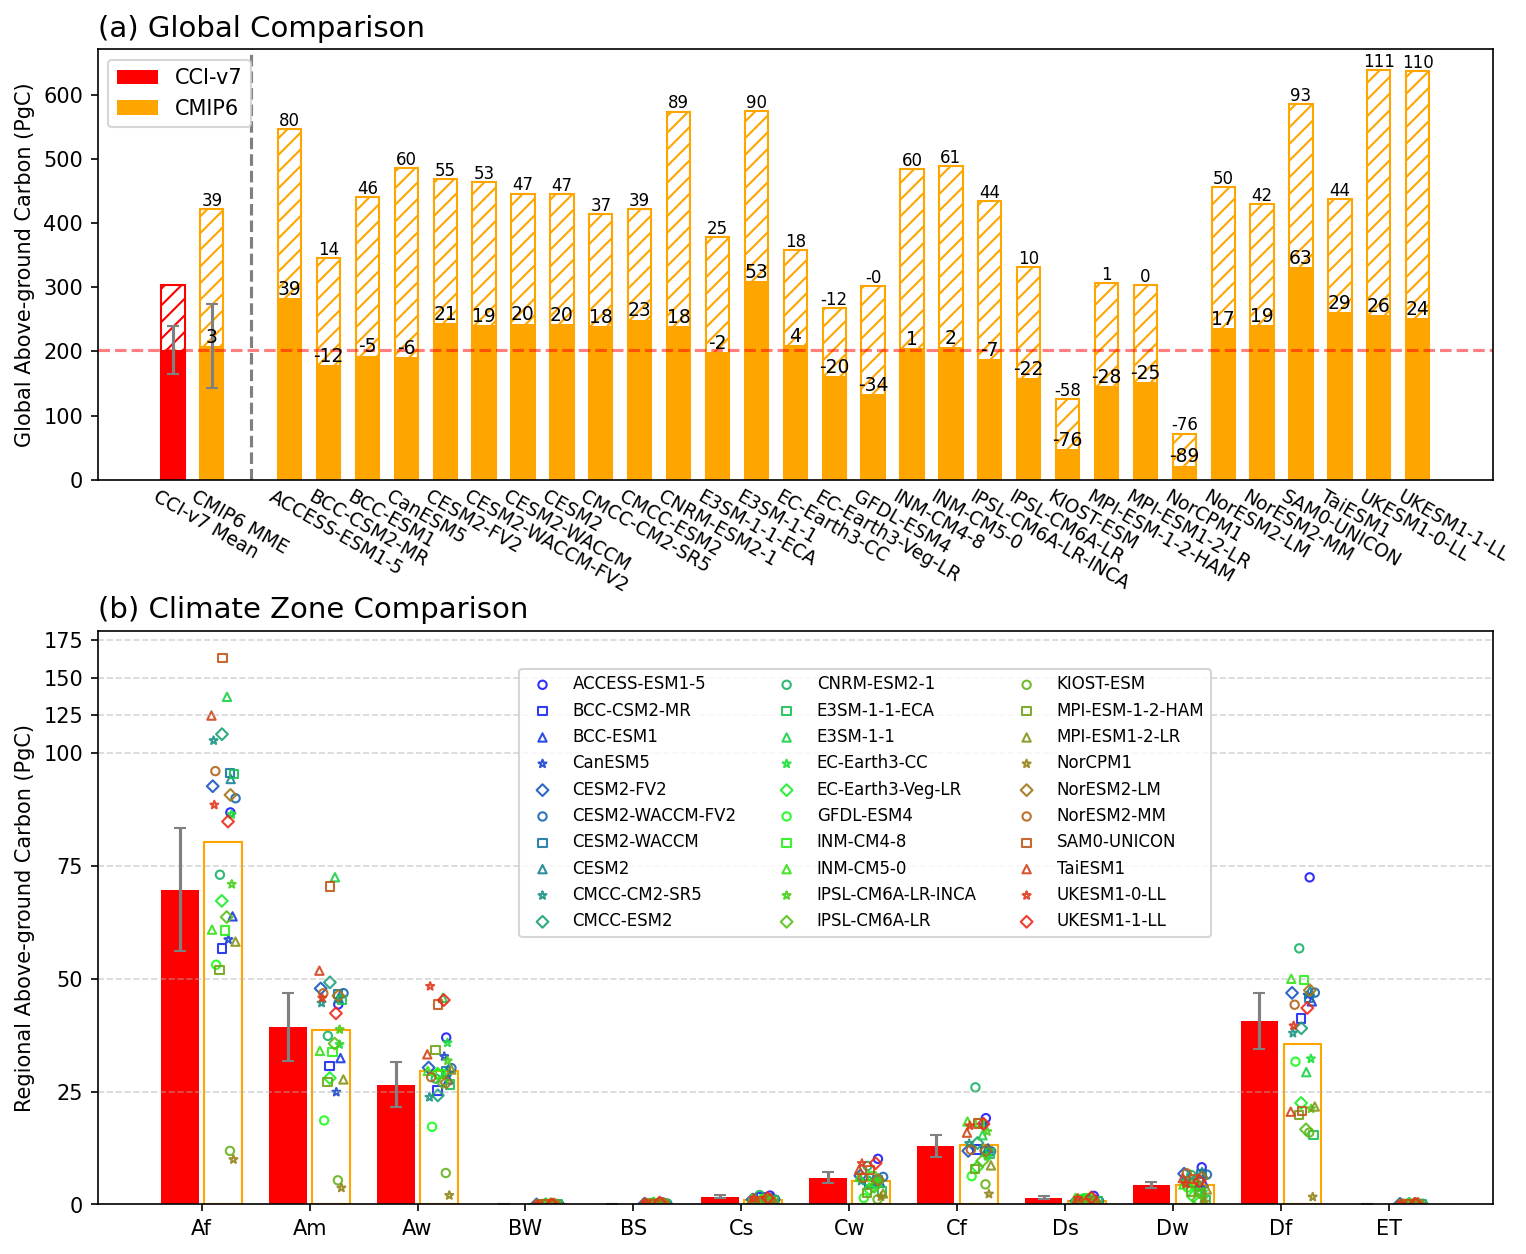

In [4]:
### ----- Supplementary Figure 2 ----- ###
print("New fig.1 under Hansen tree mask")
MASK = (treemask1 & ValidMask).astype(np.float64)  ### new mask
MASK[MASK == 0] = np.nan
ESA_datat = ESA_data * MASK
ESA_stdt = ESA_std * MASK
CMIP_datat = CMIP_data0 * MASK

### ----- Global Comparison & Climate Zone Comparison ----- ###
fig, axs = plt.subplots(2, 1, figsize=(12, 10), dpi=150,
    gridspec_kw={"height_ratios":[3, 4], "hspace":0.3})
ax = axs[0]

### ESACCI V7 mean
esaSum0 = getGlobal(ESA_data)
esaSumt = getGlobal(ESA_datat)
ax.axhline(y=esaSumt, color="red", linestyle="--", alpha=0.5)
bar1_ = ax.bar([-2], [esaSum0], width=0.6, edgecolor="red", facecolor="none", hatch="///")
bar1t = ax.bar([-2], [esaSumt], width=0.6, color="red", label="CCI-v7")
ax.errorbar([-2], [esaSumt], yerr=[getGlobal(ESA_stdt)], color="gray", capsize=3, ls="none")

### CMIP6 models
x2 = np.arange(1, modelNum+1)
y20 = np.array(list(map(getGlobal, CMIP_data0)))
y2t = np.array(list(map(getGlobal, CMIP_datat)))
bar20 = ax.bar(x2, y20, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar2t = ax.bar(x2, y2t, width=0.6, color="orange", label="CMIP6")

### CMIP6 multi-model mean
cmipMean0, cmipMeant = np.mean(y20), np.mean(y2t)
bar30 = ax.bar(-1, cmipMean0, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar3t = ax.bar(-1, cmipMeant, width=0.6, color="orange")
ax.errorbar(-1, cmipMeant, yerr=np.std(y2t), color="gray", capsize=3, ls="none")

### Difference percentage relative to ESACCI V7
ax.axvline(x=0, color="gray", linestyle="--")
ax.text(-1, cmipMean0+5, f"{(cmipMean0-esaSum0)/esaSum0*100:.0f}", ha="center", fontsize=8)
ax.text(-1, cmipMeant+5, f"{(cmipMeant-esaSumt)/esaSumt*100:.0f}", ha="center", fontsize=9)
diff0 = (y20 - esaSum0) / esaSum0 * 100
difft = (y2t - esaSumt) / esaSumt * 100
for i in range(modelNum):
    ax.text(x2[i], y20[i]+5, f"{diff0[i]:.0f}", ha="center", fontsize=8)
for i in range(modelNum):
    ax.text(x2[i], y2t[i]+5, f"{difft[i]:.0f}", ha="center", fontsize=9)
shift = 0.6

ax.set_xticks([-2-shift,-1-shift]+list(x2-shift),
              labels=["CCI-v7 Mean","CMIP6 MME"]+modelNames,
              rotation=-30, fontsize=9, ha="left")
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Global Above-ground Carbon (PgC)")
ax.legend(loc="upper left")
ax.set_title("(a) Global Comparison", fontsize=14, loc="left")

print(f"CCI-v7 Mean:  {esaSumt:.1f} PgC   ({esaSum0:.1f})")
print(f"CMIP6 MME:  {cmipMeant:.1f} PgC ± {np.std(y2t):.1f} ({cmipMean0:.1f} ± {np.std(y20):.1f})")

### ---------- Climate Zone Comparison ---------- ###
CMIP_zone = [[] for _ in range(len(cliDict))] # [zone, model]
for CMIP_map in CMIP_datat:
    for i in range(len(cliMask)):
        temp = CMIP_map.copy()
        temp[~cliMask[i]] = np.nan
        CMIP_zone[i].append(getGlobal(temp))
CMIP_zone = np.array(CMIP_zone)

ax = axs[1]
x = np.arange(0, len(cliDict))

### Climate Zone mean
y1 = [getGlobal(ESA_datat, mask=mask) for mask in cliMask]
bar1 = ax.bar(x-0.2, y1, width=0.35, color="red")
stds = [getGlobal(ESA_stdt, mask=mask) for mask in cliMask]
ax.errorbar(x-0.2, y1, yerr=stds, color="gray", capsize=3, ls="none")

y2 = CMIP_zone.mean(axis=1)
bar2 = ax.bar(x+0.2, y2, width=0.35, facecolor="none", edgecolor="orange")

### Scatter all CMIP6 models
from matplotlib.colors import LinearSegmentedColormap
colors = [(0.1, 0.1, 1.), (0.1, 1., 0.1), (1., 0.1, 0.1)]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)
markers = ['o', 's', '^', '*', 'D']
shift = rng.uniform(-0.12, 0.12, size=modelNum)  # 随机偏移避免重叠
for i in range(modelNum):
    color = cmap(i/modelNum, alpha=0.8)
    marker = markers[i%len(markers)]
    ax.scatter(x+0.2+shift[i], CMIP_zone[:,i], s=16, alpha=0.9,
        facecolor="none", edgecolor=color, marker=marker, label=modelNames[i])

ax.set_yscale("function", functions=(   # scale y-axis
    lambda x: np.where(x<=100, x, 100 + (x-100)/3),  # forward
    lambda y: np.where(y<=100, y, 100 + (y-100)*3),  # inverse
))
ax.legend(loc="center", bbox_to_anchor=(0.55, 0.7), ncol=3, fontsize=8)
ax.set_ylabel("Regional Above-ground Carbon (PgC)")
ax.set_xticks(x, labels=cliDict.keys())
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.set_title("(b) Climate Zone Comparison", fontsize=14, loc="left")

print("\t".join([" "] + list(cliDict.keys())))
print("\t".join(["ESA-v7:"] + [f"{i:.2f}" for i in y1]))
print("\t".join(["CMIP6:"] + [f"{i:.2f}" for i in y2]))
print("\t".join(["Diff:"] + [f"{j-i:.2f}" if i!=0 else "--" for i,j in zip(y1,y2)]))
print("\t".join([" "] + [f"{(j-i)/i*100:+.1f}%" if i!=0 else "--" for i,j in zip(y1,y2)]))

plt.show(fig)  # fig 1
plt.close(fig)


Tree Fraction & AGB


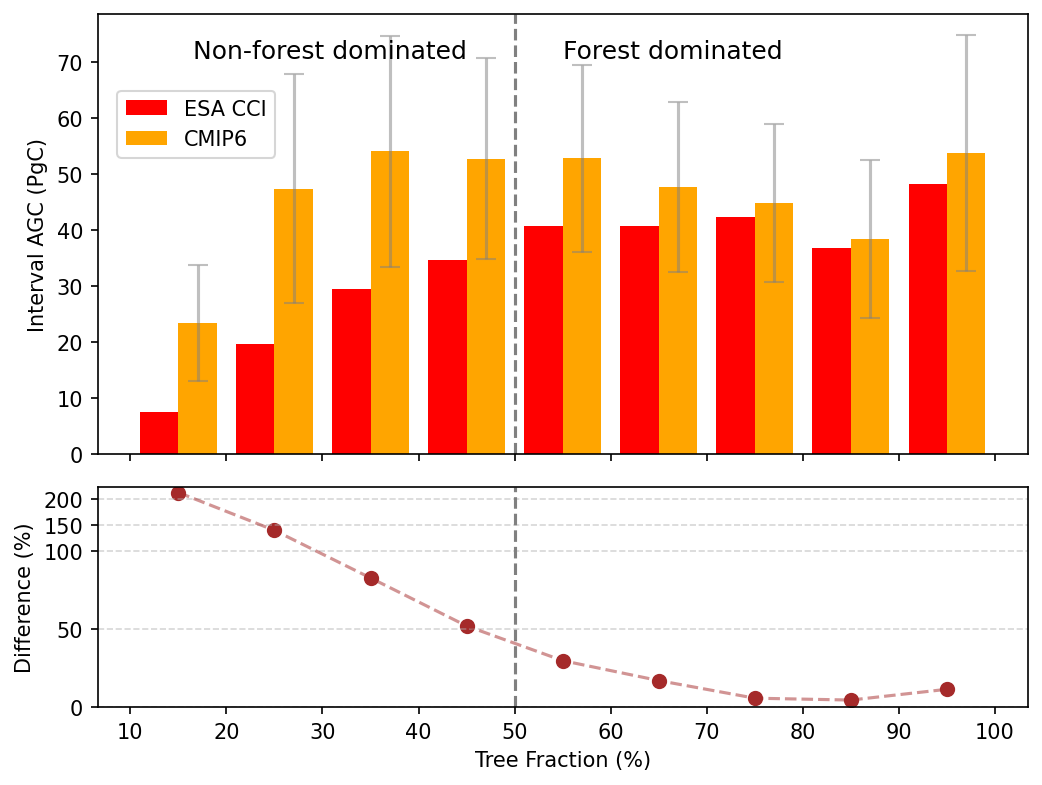

In [5]:
### ----- Supplementary Figure 4 ----- ###
print("Tree Fraction & AGB")

bounds = np.arange(10, 101, 10)
masks = []  # [P, lat, lon]
for i in range(len(bounds)-1):
    masks.append((treeFrac>bounds[i]) & (treeFrac<=bounds[i+1]))
ESA_AGBs = np.array([getGlobal(ESA_data, mask=m) for m in masks])  # [P]
CMIP_AGBs = np.array([[getGlobal(data, mask=m) for m in masks] for data in CMIP_data0])
Percentage = (CMIP_AGBs / ESA_AGBs - 1) * 100  # [N, P]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=150,
        gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.1}, sharex=True)

ax1.bar(bounds[:-1]+3, ESA_AGBs, width=4, color="red", label="ESA CCI")
ax1.bar(bounds[:-1]+7, CMIP_AGBs.mean(axis=0), width=4, color="orange", label="CMIP6")
ax1.errorbar(bounds[:-1]+7, CMIP_AGBs.mean(axis=0), yerr=CMIP_AGBs.std(axis=0),
             fmt="none", color="gray", alpha=0.5, capsize=5)
ax1.axvline(x=50, color="gray", linestyle="--")
ax1.set_ylabel("Interval AGC (PgC)")
ax1.legend(bbox_to_anchor=(0.01, 0.75), loc="center left")

ax2.scatter(bounds[:-1]+5, Percentage.mean(axis=0), color="brown", s=40)
ax2.plot(bounds[:-1]+5, Percentage.mean(axis=0), color="brown", linestyle="--", alpha=0.5)
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)
ax2.axvline(x=50, color="gray", linestyle="--")
#ax2.axhline(y=0, color="lightgray", linestyle="-")
ax2.set_yscale("function", functions=(   # scale y-axis
    lambda x: np.where(x<=100, x, 100 + (x-100)/3),  # forward
    lambda y: np.where(y<=100, y, 100 + (y-100)*3),  # inverse
))
ax2.set_ylabel("Difference (%)")
ax2.set_ylim(0, None)

ax1.text(45, 0.9*ax1.get_ylim()[1], "Non-forest dominated", ha="right", fontsize=12)
ax1.text(55, 0.9*ax1.get_ylim()[1], "Forest dominated", ha="left", fontsize=12)
ax2.set_xticks(bounds)
ax2.set_xlabel("Tree Fraction (%)")

plt.show(fig)
plt.close(fig)


Global confidence of bias
Over 1 SE: 2336/3518 (66.4%)
Over 3 SE: 901/3518 (25.6%)


C:\Users\Admin\AppData\Local\Temp\ipykernel_27324\1307973729.py:11: RuntimeWarning: Mean of empty slice
  diff = np.nanmean(CMIP_datat, axis=0) - ESA_datat


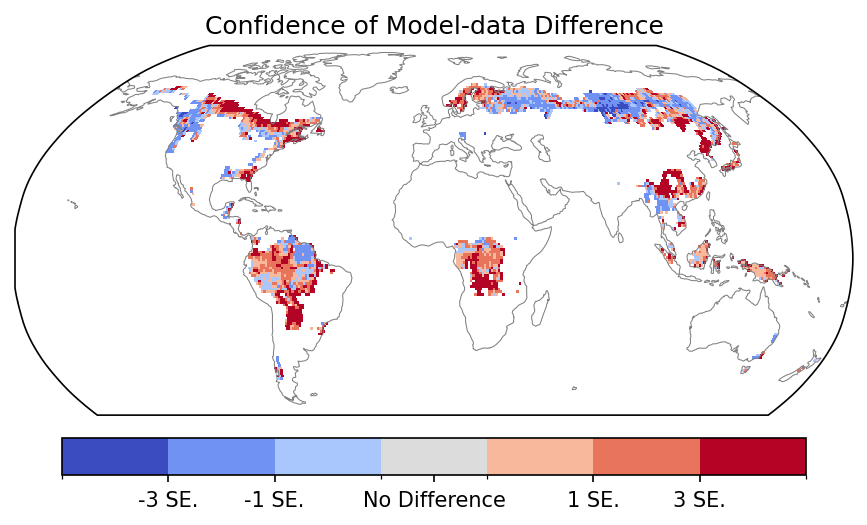

In [6]:
### ----- Supplementary Figure 5 ----- ###
from matplotlib.colors import ListedColormap, BoundaryNorm

print("Global confidence of bias")

TreeMask = TreeMask.astype(np.float32)
TreeMask[TreeMask == 0] = np.nan
ESA_datat = ESA_data * TreeMask
CMIP_datat = CMIP_data0 * TreeMask

diff = np.nanmean(CMIP_datat, axis=0) - ESA_datat
diff_ratio = diff / (ESA_std + 1e-6)
valid_num = np.sum(~np.isnan(diff_ratio))
num_1se = np.sum(np.abs(diff_ratio) > 1)
num_3se = np.sum(np.abs(diff_ratio) > 3)
print(f"Over 1 SE: {num_1se}/{valid_num} ({num_1se/valid_num:.1%})")
print(f"Over 3 SE: {num_3se}/{valid_num} ({num_3se/valid_num:.1%})")

confidence = np.full_like(diff_ratio, np.nan)
confidence[diff_ratio == 0] = 0
confidence[diff_ratio < 0] = -1
confidence[diff_ratio < -1] = -2  # -1 SE
confidence[diff_ratio < -3] = -3   # -3 SE
confidence[diff_ratio > 0] = 1
confidence[diff_ratio > 1] = 2    # 1 SE
confidence[diff_ratio > 3] = 3    # 3 SE

# 定义颜色映射
base_cmap = plt.cm.coolwarm  # 基准cmap
color_values = np.arange(-3, 4)
n_colors = len(color_values)
colors = base_cmap(np.linspace(0, 1, n_colors))
my_cmap = ListedColormap(colors)
# 创建BoundaryNorm来映射数据到颜色
bounds = color_values - 0.5
bounds = np.append(bounds, bounds[-1]+1)
norm = BoundaryNorm(bounds, my_cmap.N)

fig, ax = plt.subplots(figsize=(8, 4), dpi=150,
        subplot_kw={"projection":ccrs.Robinson()})
img = ax.pcolormesh(lon, lat[30:], confidence[30:], cmap=my_cmap, norm=norm,
        transform=ccrs.PlateCarree(), shading="flat")  # 60S-90N
ax.coastlines(color="gray", linewidth=0.5)
ax.set_title("Confidence of Model-data Difference")
cbar = fig.colorbar(img, ax=ax, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.set_ticks([-2.5, -1.5, 0, 1.5, 2.5],
        labels=["-3 SE.", "-1 SE.", "No Difference", "1 SE.", "3 SE."])

plt.show(fig)
plt.close(fig)
